In [2]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current working directory:
C:\Users\manav\sentiment_analysis_project

Files and folders here:
['.ipynb_checkpoints', 'sentiment_analysis.ipynb', 'TestReviews.csv', 'TrainingDataNegative.txt', 'TrainingDataPositive.txt']


In [4]:
from pathlib import Path

data_dir = Path("sentiment_data")

for file in data_dir.iterdir():
    if file.is_file():
        print(file.name)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'sentiment_data'

In [5]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles and folders available:")
print(os.listdir())

Current directory:
C:\Users\manav\sentiment_analysis_project

Files and folders available:
['.ipynb_checkpoints', 'sentiment_analysis.ipynb', 'TestReviews.csv', 'TrainingDataNegative.txt', 'TrainingDataPositive.txt']


In [6]:
data_dir = Path(r"C:\Users\manav\Desktop\sentiment_data")

for file in data_dir.iterdir():
    if file.is_file():
        print(file.name)

TestReviews.csv
TrainingDataNegative.txt
TrainingDataPositive.txt


In [7]:
from pathlib import Path
import pandas as pd

data_dir = Path(r"C:\Users\manav\Desktop\sentiment_data")  # Change if your files are in another folder

positive_file = data_dir / "TrainingDataPositive.txt"
negative_file = data_dir / "TrainingDataNegative.txt"
test_file = data_dir / "TestReviews.csv"

print("Positive file exists:", positive_file.exists())
print("Negative file exists:", negative_file.exists())
print("Test file exists:", test_file.exists())

Positive file exists: True
Negative file exists: True
Test file exists: True


In [8]:
with open(positive_file, "r", encoding="utf-8") as f:
    print("POSITIVE REVIEWS:")
    for _ in range(5):
        print(repr(f.readline()))

with open(negative_file, "r", encoding="utf-8") as f:
    print("\nNEGATIVE REVIEWS:")
    for _ in range(5):
        print(repr(f.readline()))

POSITIVE REVIEWS:
'This paddle sport supply store is stocked to the rafters with a staggering selection of everything you could possibly ever need to get your crazy paddle on.  Owners, Jeff and Darren, are friendly and quick to answer even silly newbie questions.\n'
"This place is a veritable candy store for outdoor enthusiasts, especially kayak and canoers. Really friendly and knowledgeable people ready to help. They have a huge inventory of watercraft out back, so don't get fooled by the size of the building or showroom. The building backs up to a channel that makes it possible to test drive a kayak or canoe. One word of warning - you will want to buy something, anything, when you walk in.\n"
"I've done quite a bit of canoeing and kayaking - lakes, rivers, whitewater, but, never actually owned my own Kayak.  I live on the Sugar River and was looking for a nice boat that had a good balance of maneuverability, stability, tracking, and efficiency so I could use it on the river but, also

In [9]:
test_df = pd.read_csv(test_file)

print("Shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
display(test_df.head())

Shape: (4321, 2)
Columns: ['review', 'class']


,review,class
0,Fantastic spot for an even or a quite cocktail...,1
1,"Love, love, love the calamari. It's so good an...",1
2,"Love this place. Stiff martinis and cocktails,...",1
3,It's everything a great cocktail bar should be...,1
4,"I came here before a pirates game, so it was a...",1


In [10]:
print("Dataset shape:", test_df.shape)

print("\nClass counts:")
print(test_df["class"].value_counts(dropna=False))

print("\nMissing values:")
print(test_df.isnull().sum())

print("\nDuplicate reviews:", test_df["review"].duplicated().sum())

display(test_df.sample(5, random_state=42))

Dataset shape: (4321, 2)

Class counts:
class
1    2989
0    1332
Name: count, dtype: int64

Missing values:
review    0
class     0
dtype: int64

Duplicate reviews: 173


,review,class
1073,Awesome! It is sooo much fun for me to take p...,1
856,The Rhythm Room was the first blues bar I visi...,1
1222,"As a former BR employee, I'm very hard on my s...",1
3406,"Sadly, the professionalism of the front desk n...",0
2250,4.5 .5 off for hard ass tires.This is awesome ...,1


In [11]:
from pathlib import Path
import pandas as pd

data_dir = Path(r"C:\Users\manav\Desktop\sentiment_data")  # Change this if your files are in another folder

with open(data_dir / "TrainingDataPositive.txt",
          "r", encoding="utf-8") as f:
    positive_reviews = f.readlines()

with open(data_dir / "TrainingDataNegative.txt",
          "r", encoding="utf-8") as f:
    negative_reviews = f.readlines()

train_df = pd.DataFrame({
    "review": positive_reviews + negative_reviews,
    "sentiment": (
        [1] * len(positive_reviews)
        + [0] * len(negative_reviews)
    )
})

train_df["review"] = train_df["review"].str.strip()
train_df = train_df[train_df["review"] != ""]

print("Training dataset shape:", train_df.shape)
print(train_df["sentiment"].value_counts())
display(train_df.head())

Training dataset shape: (11210, 2)
sentiment
1    7961
0    3249
Name: count, dtype: int64


,review,sentiment
0,This paddle sport supply store is stocked to t...,1
1,This place is a veritable candy store for outd...,1
2,I've done quite a bit of canoeing and kayaking...,1
3,Great place to rent kayaks for a little bit of...,1
4,"Amazing selection of product, and very knowled...",1


In [12]:
# Make a copy so the original data remains unchanged
test_df = test_df.copy()

# Remove leading/trailing whitespace
test_df["review"] = test_df["review"].astype(str).str.strip()

# Remove empty reviews
test_df = test_df[test_df["review"] != ""]

# Remove exact duplicate reviews
test_df = test_df.drop_duplicates(
    subset=["review"]
).reset_index(drop=True)

# Check the result
print("Shape after cleaning:", test_df.shape)
print("\nClass distribution:")
print(test_df["class"].value_counts())

print("\nDuplicate reviews remaining:",
      test_df["review"].duplicated().sum())

Shape after cleaning: (4146, 2)

Class distribution:
class
1    2861
0    1285
Name: count, dtype: int64

Duplicate reviews remaining: 0


In [13]:
from pathlib import Path
import pandas as pd

data_dir = Path(".")  # Folder containing the two .txt files

with open(data_dir / "TrainingDataPositive.txt",
          "r", encoding="utf-8") as f:
    positive_reviews = f.readlines()

with open(data_dir / "TrainingDataNegative.txt",
          "r", encoding="utf-8") as f:
    negative_reviews = f.readlines()

train_df = pd.DataFrame({
    "review": positive_reviews + negative_reviews,
    "sentiment": (
        [1] * len(positive_reviews)
        + [0] * len(negative_reviews)
    )
})

train_df["review"] = train_df["review"].str.strip()
train_df = train_df[train_df["review"] != ""]
train_df = train_df.drop_duplicates(
    subset=["review"]
).reset_index(drop=True)

print("Training shape:", train_df.shape)
print("\nTraining class counts:")
print(train_df["sentiment"].value_counts())

display(train_df.head())

Training shape: (10282, 2)

Training class counts:
sentiment
1    7269
0    3013
Name: count, dtype: int64


,review,sentiment
0,This paddle sport supply store is stocked to t...,1
1,This place is a veritable candy store for outd...,1
2,I've done quite a bit of canoeing and kayaking...,1
3,Great place to rent kayaks for a little bit of...,1
4,"Amazing selection of product, and very knowled...",1


In [14]:
from sklearn.model_selection import train_test_split

X = train_df["review"]
y = train_df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 8225
Testing samples: 2057

Training label distribution:
sentiment
1    5815
0    2410
Name: count, dtype: int64

Testing label distribution:
sentiment
1    1454
0     603
Name: count, dtype: int64


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    )
])

print("Model pipeline created successfully!")

Model pipeline created successfully!


In [16]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Accuracy: 0.947
Precision: 0.9641
Recall: 0.9608
F1-score: 0.9625

Detailed classification report:
              precision    recall  f1-score   support

    Negative       0.91      0.91      0.91       603
    Positive       0.96      0.96      0.96      1454

    accuracy                           0.95      2057
   macro avg       0.94      0.94      0.94      2057
weighted avg       0.95      0.95      0.95      2057



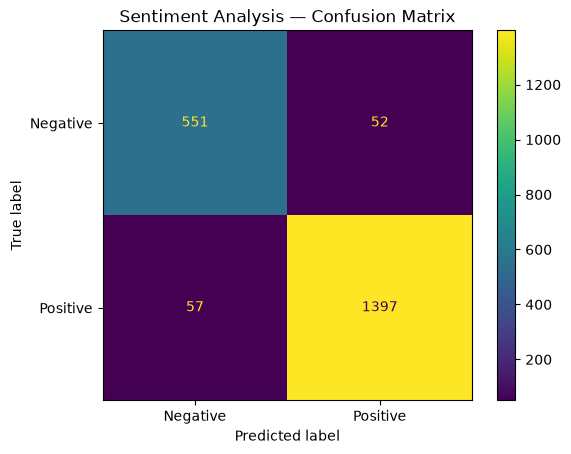

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Negative", "Positive"]
)
plt.title("Sentiment Analysis — Confusion Matrix")
plt.show()

In [18]:
def predict_sentiment(review):
    prediction = model.predict([review])[0]
    probabilities = model.predict_proba([review])[0]

    classes = model.named_steps["classifier"].classes_
    confidence = probabilities[list(classes).index(prediction)]

    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Model confidence: {confidence:.2%}")


predict_sentiment("The staff was friendly and the service was excellent!")

Review: The staff was friendly and the service was excellent!
Predicted sentiment: Positive
Model confidence: 92.93%


In [19]:
predict_sentiment("The food was terrible and the staff was rude.")

predict_sentiment("The experience was okay, nothing special.")

predict_sentiment("I absolutely loved this place and would visit again!")

Review: The food was terrible and the staff was rude.
Predicted sentiment: Negative
Model confidence: 96.28%
Review: The experience was okay, nothing special.
Predicted sentiment: Negative
Model confidence: 78.35%
Review: I absolutely loved this place and would visit again!
Predicted sentiment: Positive
Model confidence: 66.56%


In [20]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8225,)
X_test: (2057,)
y_train: (8225,)
y_test: (2057,)


In [21]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )),
        ("classifier", MultinomialNB())
    ])
}

print("Both models are ready!")

Both models are ready!


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import time

results = []

for name, candidate in models.items():
    start_time = time.time()

    candidate.fit(X_train, y_train)
    predictions = candidate.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Time (seconds)": round(time.time() - start_time, 2)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,Time (seconds)
0,Logistic Regression,0.9470,0.9641,0.9608,0.9625,7.93
1,Naive Bayes,0.9159,0.9046,0.9849,0.9430,7.45


In [23]:
# Check the class distribution in the training data
print("Training sentiment distribution:")
print(y_train.value_counts())

print("\nTraining sentiment percentages:")
print(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

Training sentiment distribution:
sentiment
1    5815
0    2410
Name: count, dtype: int64

Training sentiment percentages:
sentiment
1    70.7%
0    29.3%
Name: proportion, dtype: str


In [24]:
from sklearn.metrics import classification_report

lr_predictions = models["Logistic Regression"].predict(X_test)

print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.91      0.91      0.91       603
    Positive       0.96      0.96      0.96      1454

    accuracy                           0.95      2057
   macro avg       0.94      0.94      0.94      2057
weighted avg       0.95      0.95      0.95      2057



In [25]:

from collections import Counter
import re
import matplotlib.pyplot as plt

# Separate the reviews by sentiment
positive_reviews = train_df.loc[
    train_df["sentiment"] == 1, "review"
]

negative_reviews = train_df.loc[
    train_df["sentiment"] == 0, "review"
]

# Common words to exclude because they add little meaning
stop_words = set("""
a an the and or but is are was were be been being
to of in on for with at by from this that it its
i me my we our you your he she they them their
as do does did have has had very really just so
""".split())

def get_common_words(reviews, top_n=15):
    words = []

    for review in reviews:
        # Extract words and convert them to lowercase
        tokens = re.findall(r"\b[a-zA-Z]+\b", review.lower())

        # Remove common words
        words.extend(
            word for word in tokens
            if word not in stop_words and len(word) > 2
        )

    return Counter(words).most_common(top_n)

positive_common = get_common_words(positive_reviews)
negative_common = get_common_words(negative_reviews)

print("Most common words in positive reviews:")
print(positive_common)

print("\nMost common words in negative reviews:")
print(negative_common)


Most common words in positive reviews:
[('place', 4529), ('food', 4294), ('great', 4215), ('not', 3507), ('there', 3437), ('good', 3411), ('all', 3227), ('here', 3073), ('can', 2958), ('like', 2815), ('out', 2639), ('one', 2597), ('get', 2418), ('time', 2318), ('some', 2109)]

Most common words in negative reviews:
[('not', 4011), ('food', 2877), ('there', 2229), ('place', 1954), ('like', 1802), ('out', 1756), ('all', 1601), ('would', 1527), ('when', 1527), ('one', 1525), ('what', 1409), ('get', 1374), ('back', 1364), ('service', 1361), ('time', 1351)]


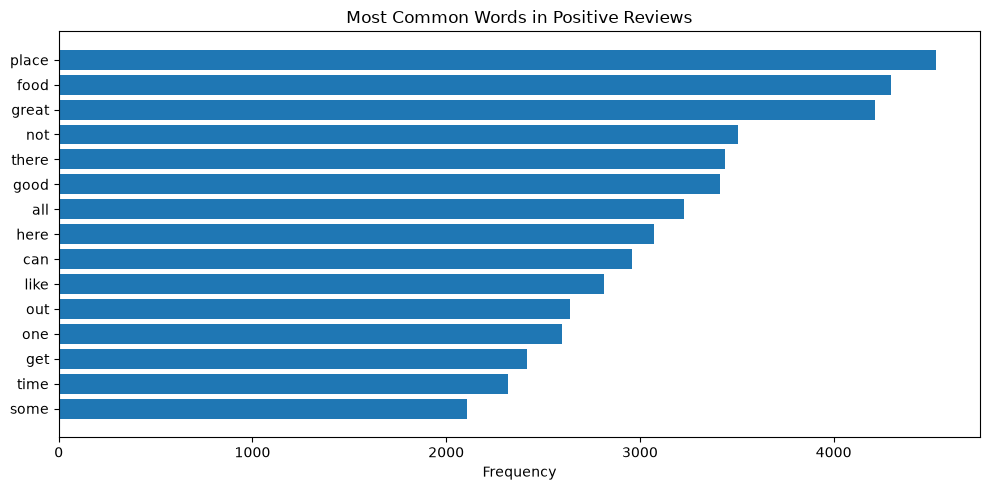

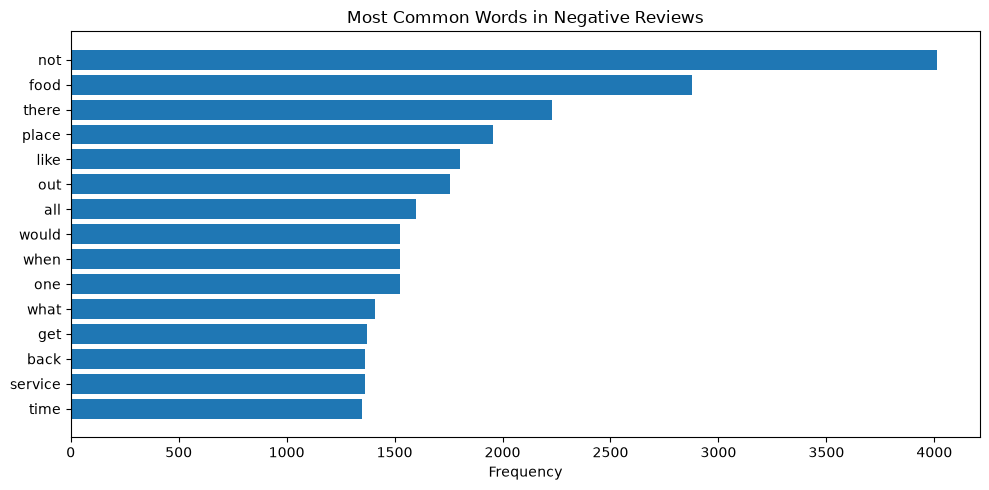

In [26]:

# Extract labels and counts for plotting
pos_words, pos_counts = zip(*positive_common)
neg_words, neg_counts = zip(*negative_common)

plt.figure(figsize=(10, 5))
plt.barh(pos_words[::-1], pos_counts[::-1])
plt.title("Most Common Words in Positive Reviews")
plt.xlabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.barh(neg_words[::-1], neg_counts[::-1])
plt.title("Most Common Words in Negative Reviews")
plt.xlabel("Frequency")
plt.tight_layout()
plt.show()


In [27]:
import joblib
from pathlib import Path

Path("saved_model").mkdir(exist_ok=True)

joblib.dump(
    models["Logistic Regression"],
    "saved_model/sentiment_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [28]:
import joblib

loaded_model = joblib.load(
    "saved_model/sentiment_model.pkl"
)

review = "The food was excellent and the service was wonderful."

prediction = loaded_model.predict([review])[0]
probabilities = loaded_model.predict_proba([review])[0]

sentiment = "Positive" if prediction == 1 else "Negative"
confidence = max(probabilities) * 100

print("Review:", review)
print("Predicted sentiment:", sentiment)
print(f"Model confidence: {confidence:.2f}%")

Review: The food was excellent and the service was wonderful.
Predicted sentiment: Positive
Model confidence: 76.05%


In [29]:
from pathlib import Path

model_path = Path("saved_model/sentiment_model.pkl")

print("Model file exists:", model_path.exists())
print("Model file location:", model_path.resolve())

Model file exists: True
Model file location: C:\Users\manav\sentiment_analysis_project\saved_model\sentiment_model.pkl
